# 03: the 60 fps clips (chop, forehand, backhand)

First video analysis: per-frame skeletons from both models, paddle-hand (right) wrist trajectory and speed, automatic stroke detection, per-stroke metrics, and stroke-to-stroke consistency.

Clips in `data/TableTennis1/vids/` (realme GT Neo 3, 2026-11-18, tripod): `chop60.mp4`, `derecha60.mp4` (forehand), `reves60.mp4` (backhand). The slow-motion clips (`*SM.mp4`) are inventoried in section 1 and analyzed later.

Pipeline (see `docs/WORKFLOW.md` section 9): `scripts/pose_video.py` writes the raw keypoints `data/derived/TableTennis1/vids/<clip>_keypoints_<model>.csv` (`frame, t_s, joint, x_px, y_px, conf`; time from the container's frame timestamps). Analysis functions (speed, elbow angle, stroke detection, metrics) are in `src/pose_tracker/strokes.py`, shared with notebook 04. This notebook reads those files and runs the script itself only if one is missing (RTMPose takes about 2-3 min per clip). Results kept in `test-logs/`: `ffprobe_TableTennis1_vids_2026-11-18.txt`, `strokes_TableTennis1_60fps_2026-11-18.csv`. Annotated videos go to `data/derived/TableTennis1/vids/<clip>_annotated.mp4`.

No ball and no ground truth: "contact" below means the moment of peak wrist speed, the usual proxy.

In [1]:
import csv, json, subprocess, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pose_tracker.stills import ROOT, COCO, MP_TO_COCO, EDGES, torso_px
from pose_tracker.video import frame_times, iter_frames, read_keypoints
from pose_tracker.strokes import SH, EL, WR, speed, elbow_series, detect_strokes, stroke_metrics

VIDS = ROOT / "data/TableTennis1/vids"
DER = ROOT / "data/derived/TableTennis1/vids"
LOG = ROOT / "test-logs"
DATE = "2026-11-18"
CLIPS = {"chop60": "chop", "derecha60": "forehand", "reves60": "backhand"}
MODELS = {"mediapipe": "tab:orange", "rtmpose": "tab:blue"}

## 1. What is in the files (and the "filter" look)
`ffprobe` on all five clips, including the colour and rotation metadata.

In [2]:
FIELDS = ("codec_name,pix_fmt,width,height,r_frame_rate,avg_frame_rate,nb_frames,duration,"
          "color_range,color_space,color_transfer,color_primaries")
lines, info = [], {}
for f in sorted(VIDS.glob("*.mp4")):
    out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                          f"stream={FIELDS}:stream_side_data=rotation:format_tags=com.android.capture.fps",
                          "-of", "json", str(f)], capture_output=True, text=True, check=True).stdout
    j = json.loads(out); s = j["streams"][0]
    rot = next((d["rotation"] for d in s.get("side_data_list", []) if "rotation" in d), 0)
    cap_fps = float(j["format"]["tags"]["com.android.capture.fps"])
    n, dur = int(s["nb_frames"]), float(s["duration"])
    info[f.stem] = dict(cap_fps=cap_fps, n=n, dur=dur)
    lines.append(f"{f.name:<16} {s['codec_name']} {s['width']}x{s['height']} rot {rot:>4} {s['pix_fmt']} "
                 f"range={s['color_range']} matrix={s['color_space']} transfer={s['color_transfer']} | "
                 f"file fps {eval(s['r_frame_rate']):6.2f}, capture fps {cap_fps:5.0f} | {n} frames, "
                 f"file {dur:6.1f} s, real {n/cap_fps:5.2f} s")
print("\n".join(lines))
(LOG / f"ffprobe_TableTennis1_vids_{DATE}.txt").write_text("\n".join(lines) + "\n")

chop60.mp4       h264 1920x1080 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  59.94, capture fps    60 | 505 frames, file    8.4 s, real  8.42 s
derecha60.mp4    h264 1920x1080 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  59.94, capture fps    60 | 421 frames, file    7.0 s, real  7.02 s
derechasSM.mp4   h264 1280x720 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  29.97, capture fps   480 | 5661 frames, file  188.9 s, real 11.79 s
reves60.mp4      h264 1920x1080 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  59.94, capture fps    60 | 372 frames, file    6.2 s, real  6.20 s
revesSM.mp4      h264 1280x720 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  29.97, capture fps   480 | 3056 frames, file  102.0 s, real  6.37 s


840

How to read this:
- **Not HDR, no colour filter in the data.** All clips are 8-bit H.264 with the BT.709 transfer curve (normal SDR). The pixel format is `yuvj420p`, **full range** (`color_range=pc`, values 0-255 instead of the TV range 16-235), with a BT.601 matrix (`bt470bg`). Android phones commonly write this. Some players and editors ignore the full-range flag or apply the wrong matrix, and show the clip with crushed or washed-out contrast and slightly shifted colours. That is a likely cause of the "filter" look **[assumed: depends on your player]**. OpenCV's FFmpeg backend honours the flag: the decoded frames below look like the photos, and the models only see these decoded frames.
- **Rotation -90.** The sensor stores landscape 1920x1080 plus a rotation flag. OpenCV applies it, so frames come out portrait (1080x1920). A player that ignores the flag shows the video sideways.
- **Slow motion.** `*SM.mp4` are captured at 480 fps (`com.android.capture.fps`) but written as a 30 fps file, so they play 16x slowed. The real duration is frames / 480: about 11.8 s (forehand) and 6.4 s (backhand). They are 1280x720, and the framing is tighter than at 60 fps (head and feet are cut, see the frames below). Timestamps for them must be divided by 16. Not analyzed here.

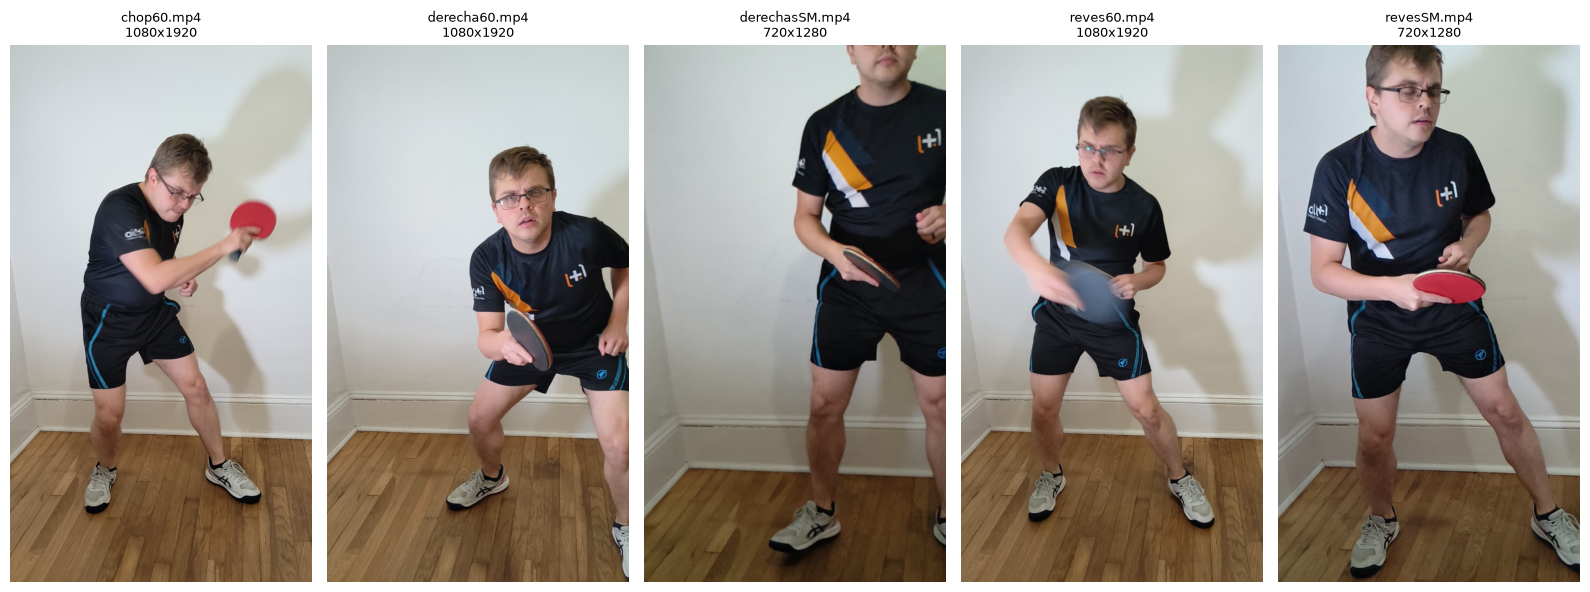

In [3]:
fig, axs = plt.subplots(1, 5, figsize=(16, 6))
for ax, f in zip(axs, sorted(VIDS.glob("*.mp4"))):
    cap = cv2.VideoCapture(str(f)); cap.set(cv2.CAP_PROP_POS_FRAMES, 60); ok, fr = cap.read(); cap.release()
    ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax.set_title(f"{f.name}\n{fr.shape[1]}x{fr.shape[0]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### Frame timing of the 60 fps clips
The container reports an average of about 59.8 fps, while the nominal rate is 59.94. Per-frame timestamps show whether frames were dropped. All later time axes use these timestamps, never index / nominal fps.

In [4]:
T = {}
for c in CLIPS:
    T[c] = frame_times(VIDS / f"{c}.mp4")
    d = 1000 * np.diff(T[c])
    print(f"{c:<10} {len(T[c])} frames, {T[c][-1]:.2f} s | dt median {np.median(d):.2f} ms, "
          f"min {d.min():.2f}, max {d.max():.2f}, gaps > 25 ms: {(d > 25).sum()}")

chop60     505 frames, 8.43 s | dt median 16.67 ms, min 16.58, max 17.16, gaps > 25 ms: 0


derecha60  421 frames, 7.03 s | dt median 16.67 ms, min 16.58, max 17.08, gaps > 25 ms: 0


reves60    372 frames, 6.21 s | dt median 16.67 ms, min 16.65, max 17.08, gaps > 25 ms: 0


## 2. Keypoints per frame (both models)
Run by `scripts/pose_video.py` (missing files are created here). MediaPipe runs in **VIDEO mode**: after the first frame it tracks its ROI from the previous landmarks instead of re-detecting, which is faster and smoother than IMAGE mode, but it can carry an error forward. RTMPose runs the YOLOX detector plus the pose model on every frame, so each frame is independent. Speed per frame is logged in `test-logs/pose-speed_<date>.csv`.

In [5]:
K = {}
for c in CLIPS:
    for m in MODELS:
        p = DER / f"{c}_keypoints_{m}.csv"
        if not p.exists():
            subprocess.run([sys.executable, str(ROOT / "scripts/pose_video.py"), str(VIDS / f"{c}.mp4"), "--model", m], check=True)
        t, xy, conf, joints = read_keypoints(p)
        assert np.allclose(t, T[c])
        if m == "mediapipe":
            xy, conf = xy[:, MP_TO_COCO], conf[:, MP_TO_COCO]
        K[c, m] = dict(t=t, xy=xy, conf=conf)
    print(c, "frames", len(t), "| frames with no person:",
          {m: int(np.isnan(K[c, m]["xy"][:, 0, 0]).sum()) for m in MODELS})

print("\nspeed (ms per frame, this laptop, CPU):")
print(open(next(LOG.glob(f"pose-speed_{DATE}.csv"))).read())

chop60 frames 505 | frames with no person: {'mediapipe': 0, 'rtmpose': 0}


derecha60 frames 421 | frames with no person: {'mediapipe': 0, 'rtmpose': 0}


reves60 frames 372 | frames with no person: {'mediapipe': 0, 'rtmpose': 0}

speed (ms per frame, this laptop, CPU):
clip,model,frames,total_s,median_ms,min_ms,median_ms_excl_first
reves60.mp4,mediapipe,372,10.3,27.0,23.2,27.0
chop60.mp4,mediapipe,505,11.3,22.0,19.4,22.0
derecha60.mp4,mediapipe,421,9.2,21.1,19.4,21.1
chop60.mp4,rtmpose,505,226.0,445.6,264.3,445.6
derecha60.mp4,rtmpose,421,161.4,374.3,339.7,374.3
reves60.mp4,rtmpose,372,152.3,376.5,308.4,376.5
revesSM.mp4,mediapipe,3056,64.3,19.6,17.4,19.6
derechasSM.mp4,mediapipe,5661,121.6,20.3,12.8,20.3
revesSM.mp4,rtmpose_track,3056,86.7,24.5,14.0,24.5
derechasSM.mp4,rtmpose_track,5661,175.2,29.1,19.6,29.1
revesSM.mp4,rtmpose_det8,3056,216.9,26.1,15.4,26.1
derechasSM.mp4,rtmpose_det8,5661,460.1,27.6,20.1,27.6
revesSM.mp4,rtmpose,3056,1156.8,368.4,308.4,368.4



## 3. Sanity check: skeletons on sample frames
Six evenly spaced frames per clip, both models (orange MediaPipe, blue RTMPose).

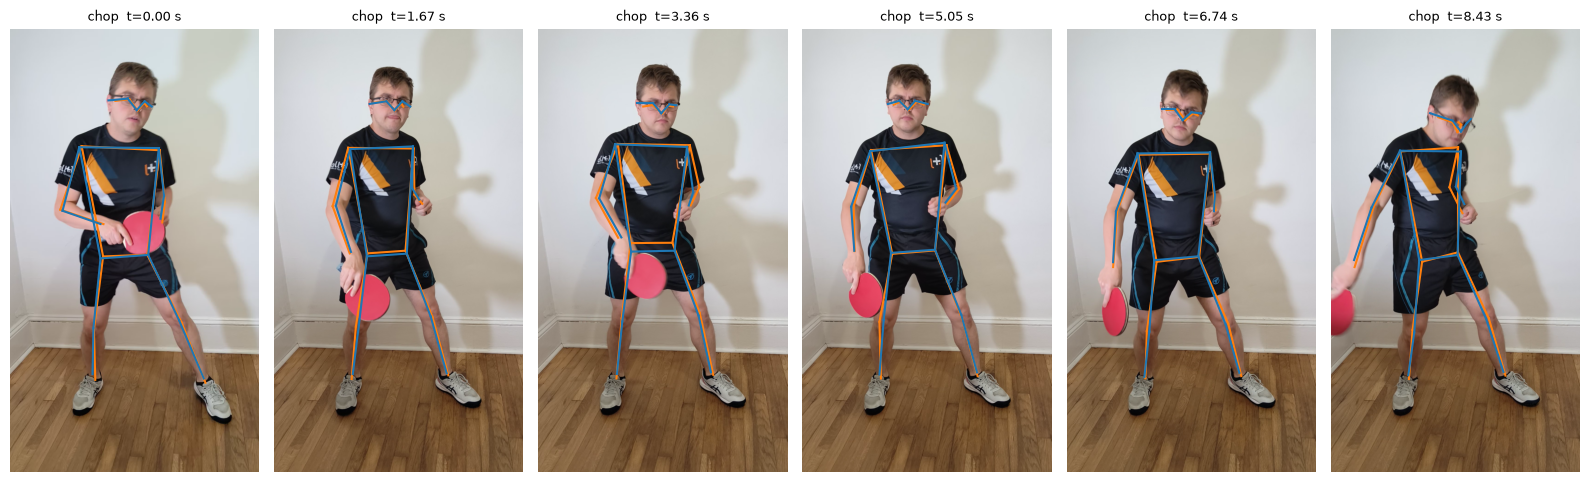

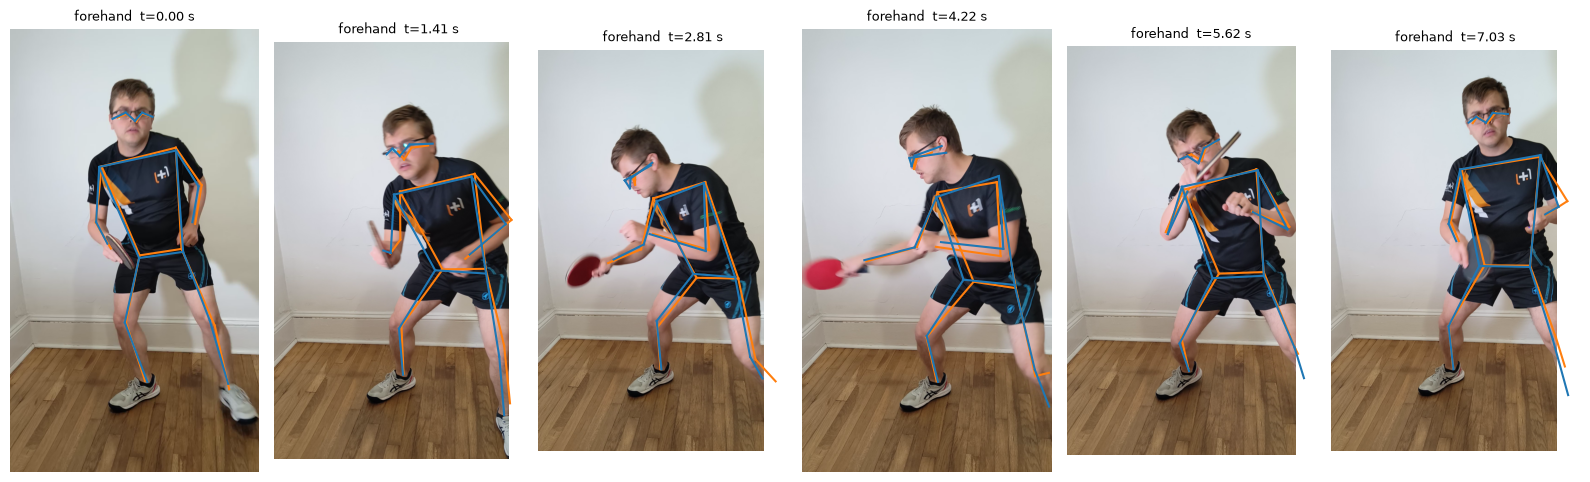

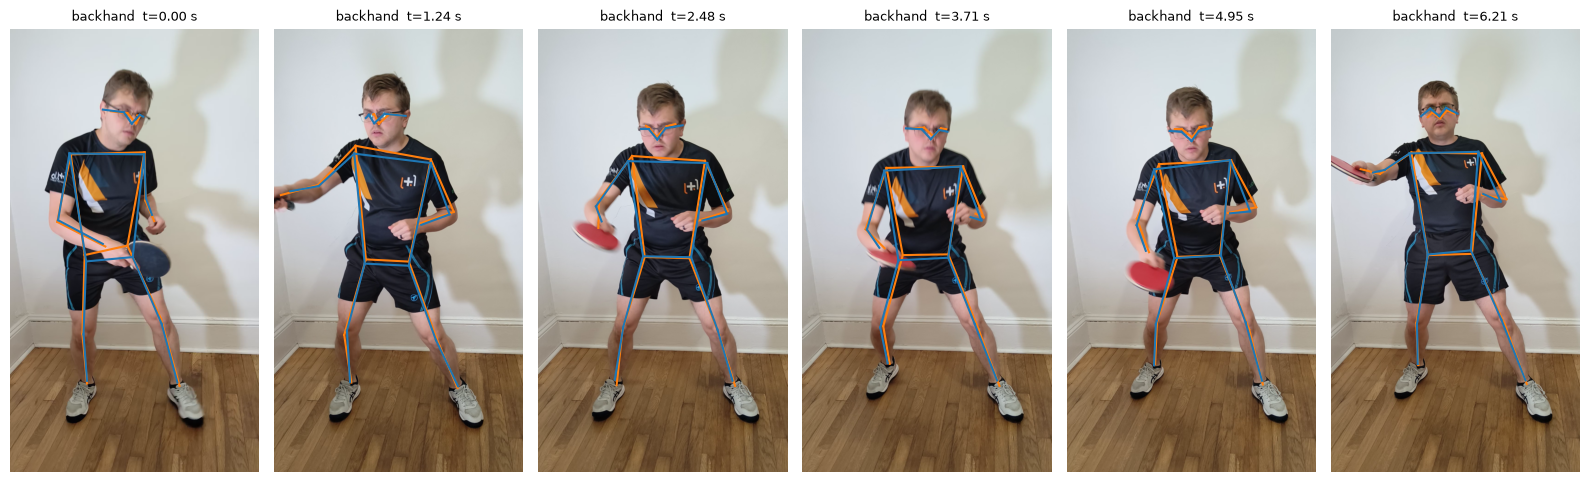

In [6]:
def grab(clip, idx):
    cap = cv2.VideoCapture(str(VIDS / f"{clip}.mp4")); frames = {}
    for i in range(max(idx) + 1):
        ok, fr = cap.read()
        if i in idx: frames[i] = fr
    cap.release(); return frames

def draw(ax, xy, col, lw=1.5):
    for a, b in EDGES:
        ax.plot(*xy[[a, b]].T, color=col, lw=lw)

for c in CLIPS:
    idx = list(np.linspace(0, len(T[c]) - 1, 6).astype(int))
    fr = grab(c, idx)
    fig, axs = plt.subplots(1, 6, figsize=(16, 5))
    for ax, i in zip(axs, idx):
        ax.imshow(cv2.cvtColor(fr[i], cv2.COLOR_BGR2RGB)); ax.axis("off")
        for m, col in MODELS.items():
            draw(ax, K[c, m]["xy"][i], col)
        ax.set_title(f"{CLIPS[c]}  t={T[c][i]:.2f} s", fontsize=9)
    plt.tight_layout(); plt.show()

## 4. Speed of the paddle hand: how much smoothing?
The wrist is the paddle proxy. Speed is in **torso lengths per second** (median shoulder-to-hip length over the clip). There is no metric scale yet: with a torso of roughly 0.5 m [assumed], 1 torso/s is about 0.5 m/s.

Speed needs a derivative, and a raw frame difference amplifies keypoint jitter. A Savitzky-Golay derivative (local polynomial fit) smooths, but a wide window also cuts the peak of a fast swing. Below: raw difference vs SG windows of 5, 9 and 15 frames (83, 150 and 250 ms) on the backhand clip, RTMPose. Frame spacing is uniform to within 0.5 ms (section 1), which SG requires.

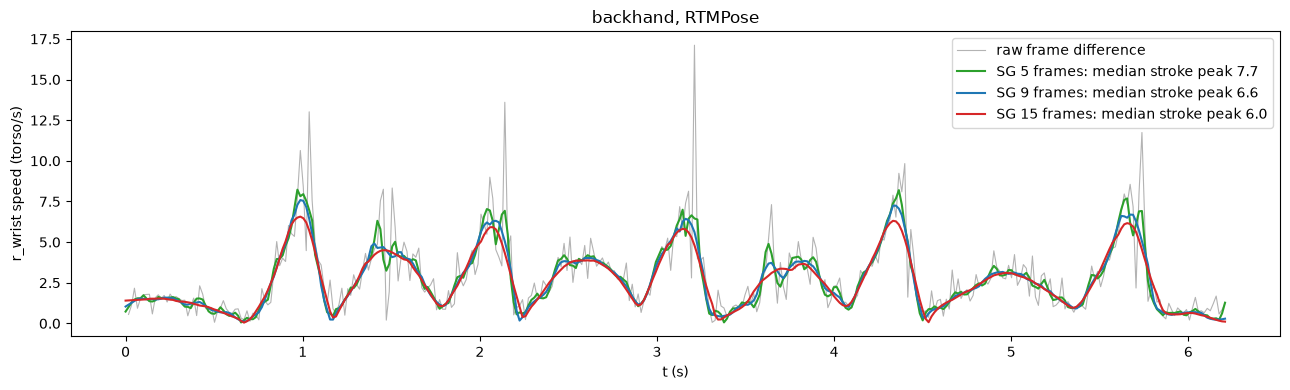

In [7]:
for k in K.values():
    k["torso"] = float(np.nanmedian([torso_px(f) for f in k["xy"]]))

k = K["reves60", "rtmpose"]; t = k["t"]; w = k["xy"][:, WR]
raw = np.linalg.norm(np.diff(w, axis=0), axis=1) / np.diff(t) / k["torso"]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t[1:], raw, color="0.7", lw=0.8, label="raw frame difference")
for win, col in [(5, "tab:green"), (9, "tab:blue"), (15, "tab:red")]:
    s = speed(w, t, win) / k["torso"]
    pk, _ = find_peaks(s, distance=int(0.6 / np.median(np.diff(t))), prominence=2)
    ax.plot(t, s, color=col, label=f"SG {win} frames: median stroke peak {np.median(s[pk]):.1f}")
ax.set_xlabel("t (s)"); ax.set_ylabel("r_wrist speed (torso/s)"); ax.legend(); ax.set_title("backhand, RTMPose")
plt.tight_layout(); plt.show()

Choice for the rest of this notebook: **SG, 9 frames (150 ms), order 2.** At 5 frames the curve still carries keypoint jitter. At 15 frames the peaks visibly flatten. Even 9 frames under-reads the true peak: the raw difference shows that the forward swing is only a few frames long at 60 fps, and with motion blur (section 7) the keypoints themselves are uncertain at that moment. Peak speeds here are therefore **lower bounds**, and comparable only at the same frame rate and filter. This is exactly what the 480 fps clips should improve.

## 5. Stroke detection and per-stroke metrics
A stroke = a peak of the smoothed wrist speed that is (a) at least 0.6 s from a higher peak, (b) at least 2 torso/s prominent and (c) at least 60 % of the clip's 99th-percentile speed. Rule (c) was added after the first run: without it, backswing and return peaks (2.6-4.1 torso/s, against 6-9 for real strokes) were counted as strokes in all three clips, and the two models disagreed on the count. The plot below is the check. Per stroke, within a window of half the median stroke period on each side of the peak:
- `t_peak`: time of peak wrist speed (contact proxy)
- `v_peak`: peak wrist speed (torso/s)
- `elbow_at_peak`: right elbow angle at the peak (image plane)
- `elbow_min`, `elbow_max`: elbow range over the stroke window
- `path`: wrist path length in the window (torso lengths)

The elbow angle is set to NaN in frames where the upper arm or forearm is shorter than 0.3 torso in the image (foreshortened, notebook 01 section 6). A second projection effect is not caught by that rule: in the forehand follow-through the hand ends at the forehead and the forearm lies on top of the upper arm in the image, so the 2D elbow angle drops to about 0 deg although neither segment is short. The real flexion is not 0. A single front camera cannot measure the elbow there.

In [8]:
WIN = 9
rows = []
for (c, m), k in K.items():
    t, xy, tor = k["t"], k["xy"], k["torso"]
    k["v"] = speed(xy[:, WR], t, WIN) / tor
    k["elbow"], short = elbow_series(xy, tor)
    k["short_frac"] = short.mean()
    k["peaks"], k["half"] = detect_strokes(k["v"], t)
    rows += [dict(clip=c, stroke=CLIPS[c], model=m, **r)
             for r in stroke_metrics(t, xy, k["v"], k["elbow"], k["peaks"], k["half"], tor)]

cols = ["clip", "stroke", "model", "n", "t_peak", "v_peak", "elbow_at_peak", "elbow_min", "elbow_max", "path"]
with open(LOG / f"strokes_TableTennis1_60fps_{DATE}.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader()
    w.writerows({k: (f"{v:.3f}" if isinstance(v, float) else v) for k, v in r.items()} for r in rows)

print(f"{'stroke':<9} {'model':<10} {'#':>2} {'t_peak':>6} {'v_peak':>6} {'el@pk':>6} {'el_min':>6} {'el_max':>6} {'path':>5}")
for r in rows:
    print(f"{r['stroke']:<9} {r['model']:<10} {r['n']:2d} {r['t_peak']:6.2f} {r['v_peak']:6.1f} {r['elbow_at_peak']:6.1f} "
          f"{r['elbow_min']:6.1f} {r['elbow_max']:6.1f} {r['path']:5.2f}")
print("\nfraction of frames with the elbow angle masked (short segment):",
      {f"{c}/{m}": round(k["short_frac"], 2) for (c, m), k in K.items()})

stroke    model       # t_peak v_peak  el@pk el_min el_max  path
chop      mediapipe   1   1.10    7.4  105.6   92.5  170.8  4.00
chop      mediapipe   2   2.73    8.3   98.3   75.7  175.2  6.12
chop      mediapipe   3   4.48    8.1  107.0   63.6  173.3  4.82
chop      mediapipe   4   6.30    7.5  114.2   61.8  171.5  5.26
chop      mediapipe   5   8.16    9.2  115.1   80.6  177.7  5.42
chop      rtmpose     1   1.09    7.1  102.9   91.9  178.4  4.14
chop      rtmpose     2   2.74    7.7  117.7   76.1  178.4  5.92
chop      rtmpose     3   4.48    7.6  114.8   66.1  173.0  4.75
chop      rtmpose     4   6.30    7.4  120.5   65.8  176.8  5.30
chop      rtmpose     5   8.19    8.2  144.9   80.2  179.9  5.12
forehand  mediapipe   1   2.32    7.2   65.3    0.5  141.3  3.54
forehand  mediapipe   2   3.33    6.2   51.7    0.2  135.8  3.15
forehand  mediapipe   3   4.33    6.6   45.5    0.0  135.8  3.15
forehand  mediapipe   4   5.42    7.4   75.8    0.1  140.6  3.23
forehand  mediapipe   5  

Speed curves with the detected strokes (x). Check by eye that every stroke you made is found once, and nothing else.

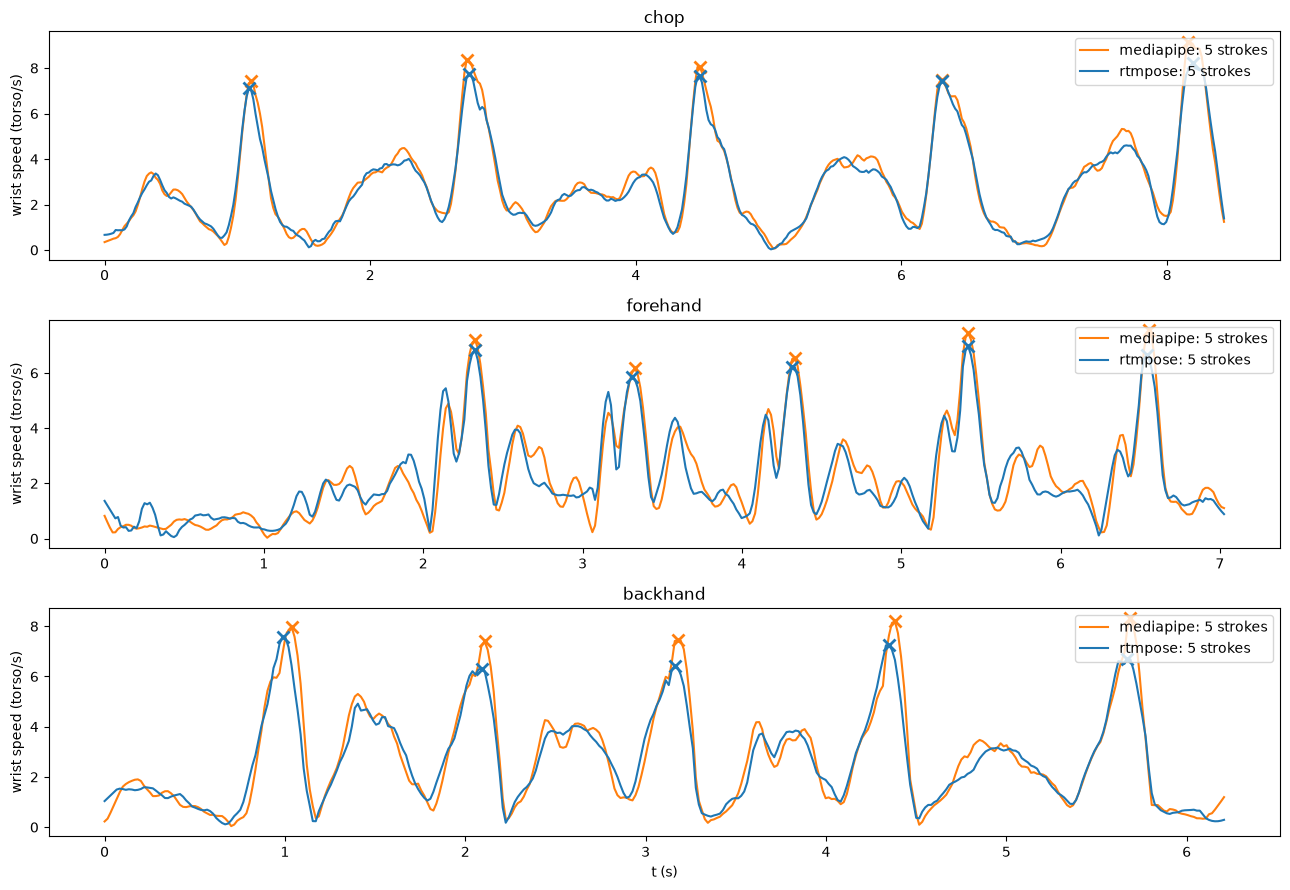

In [9]:
fig, axs = plt.subplots(3, 1, figsize=(13, 9))
for ax, c in zip(axs, CLIPS):
    for m, col in MODELS.items():
        k = K[c, m]
        ax.plot(k["t"], k["v"], color=col, label=f"{m}: {len(k['peaks'])} strokes")
        ax.plot(k["t"][k["peaks"]], k["v"][k["peaks"]], "x", color=col, ms=9, mew=2)
    ax.set_title(CLIPS[c]); ax.set_ylabel("wrist speed (torso/s)"); ax.legend(loc="upper right")
axs[-1].set_xlabel("t (s)")
plt.tight_layout(); plt.show()

## 6. Consistency across repeated strokes
Each stroke is cut to the window around its peak and aligned at the peak (t = 0). Tight bundles mean repeatable strokes. Here they also bound the measurement noise: model jitter adds to the real stroke-to-stroke variation. The table gives the mean and standard deviation over strokes.

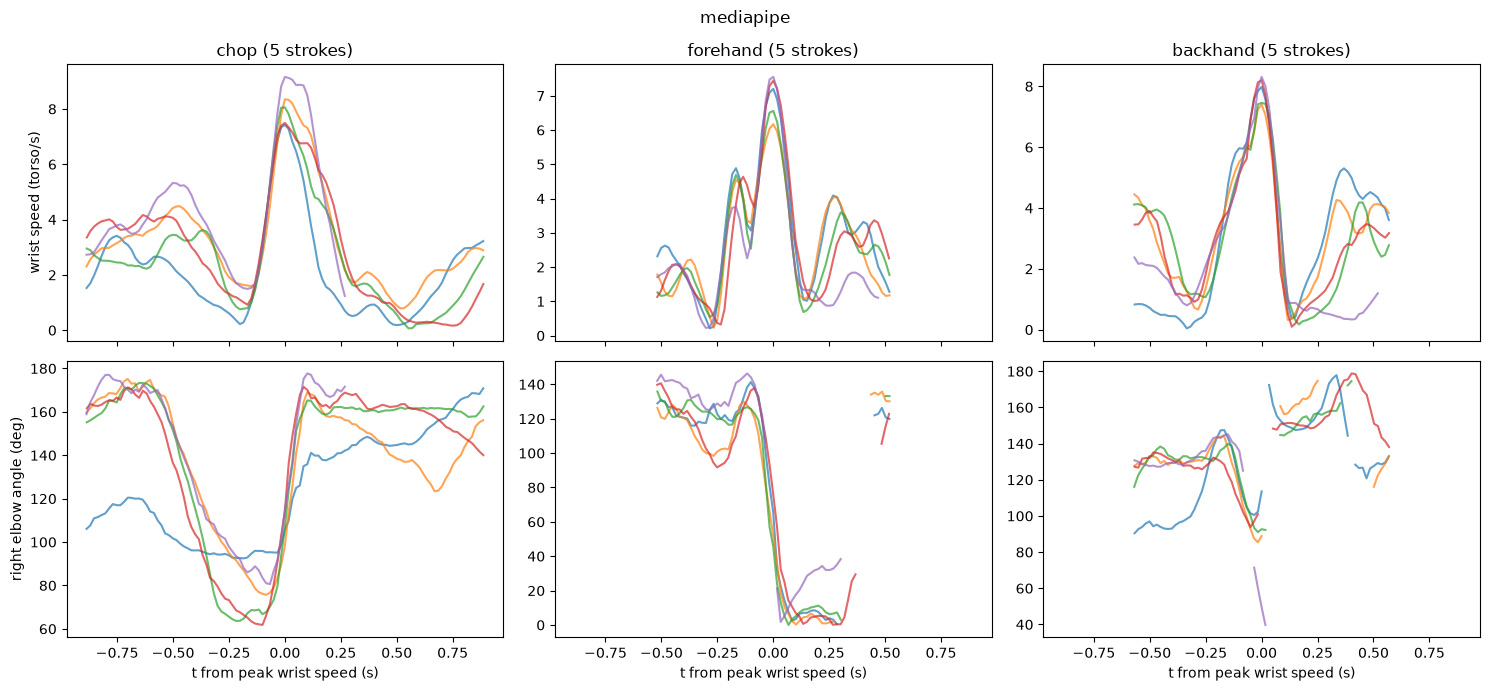

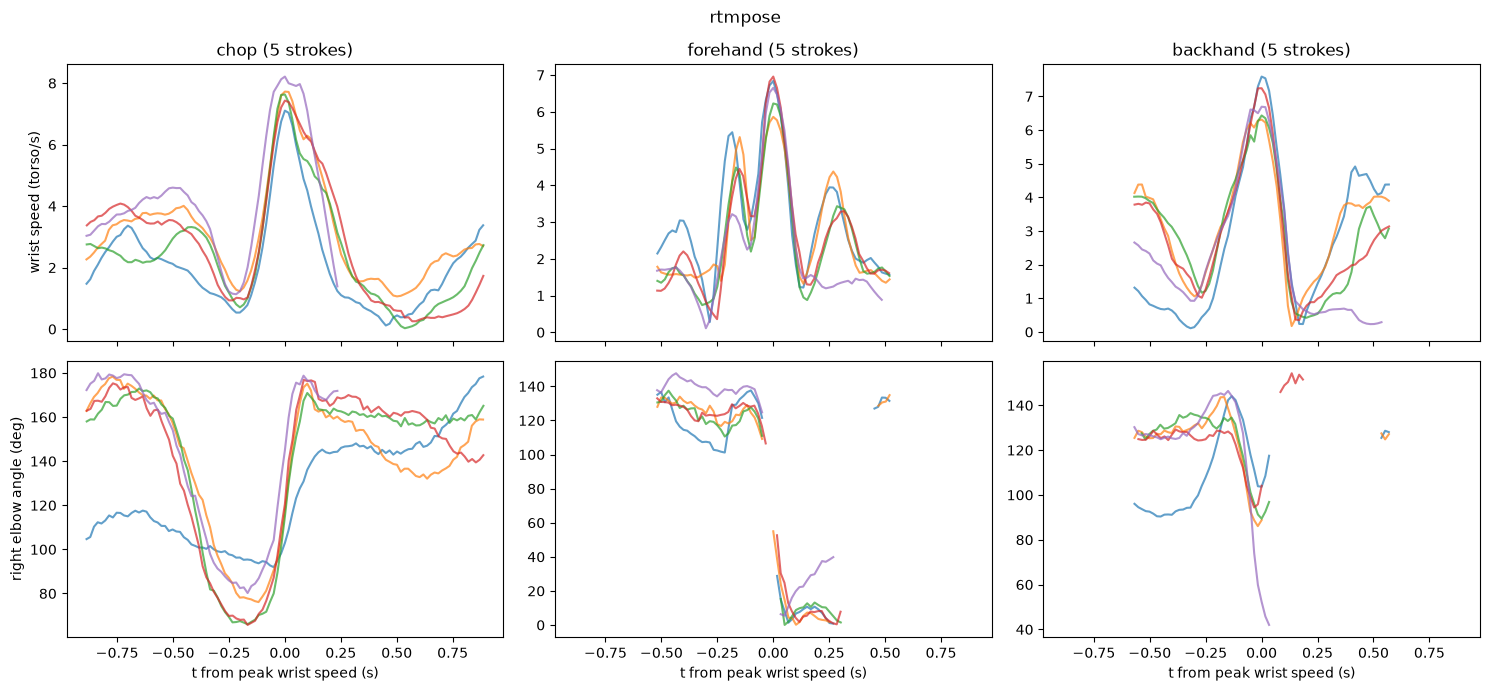

stroke    model       n        v_peak    elbow@peak  period s
chop      mediapipe   5    8.1 +-  0.6  108.0 +-  6.2      1.76
chop      rtmpose     5    7.6 +-  0.4  120.2 +- 13.7      1.78
forehand  mediapipe   5    7.0 +-  0.5   59.6 +- 11.8      1.06
forehand  rtmpose     5    6.5 +-  0.4   55.0 +-  0.0      1.05
backhand  mediapipe   5    7.9 +-  0.4   86.2 +- 23.2      1.16
backhand  rtmpose     5    6.9 +-  0.5   87.6 +- 18.9      1.17


In [10]:
for m in MODELS:
    fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for j, c in enumerate(CLIPS):
        k = K[c, m]; t = k["t"]; h = k["half"]
        for p in k["peaks"]:
            lo, hi = max(0, p - h), min(len(t), p + h + 1)
            axs[0, j].plot(t[lo:hi] - t[p], k["v"][lo:hi], alpha=0.7)
            axs[1, j].plot(t[lo:hi] - t[p], k["elbow"][lo:hi], alpha=0.7)
        axs[0, j].set_title(f"{CLIPS[c]} ({len(k['peaks'])} strokes)")
        axs[1, j].set_xlabel("t from peak wrist speed (s)")
    axs[0, 0].set_ylabel("wrist speed (torso/s)"); axs[1, 0].set_ylabel("right elbow angle (deg)")
    fig.suptitle(m); plt.tight_layout(); plt.show()

print(f"{'stroke':<9} {'model':<10} {'n':>2} {'v_peak':>13} {'elbow@peak':>13} {'period s':>9}")
for c in CLIPS:
    for m in MODELS:
        r = [x for x in rows if x["clip"] == c and x["model"] == m]
        v = np.array([x["v_peak"] for x in r]); e = np.array([x["elbow_at_peak"] for x in r])
        per = np.diff([x["t_peak"] for x in r])
        print(f"{CLIPS[c]:<9} {m:<10} {len(r):2d} {v.mean():6.1f} +- {v.std():4.1f} {np.nanmean(e):6.1f} +- {np.nanstd(e):4.1f} "
              f"{per.mean() if len(per) else np.nan:9.2f}")

Wrist path in the image, all strokes overlaid (RTMPose), on the frame at the first stroke's peak. Colour runs from the start (dark) to the end (light) of each stroke window.

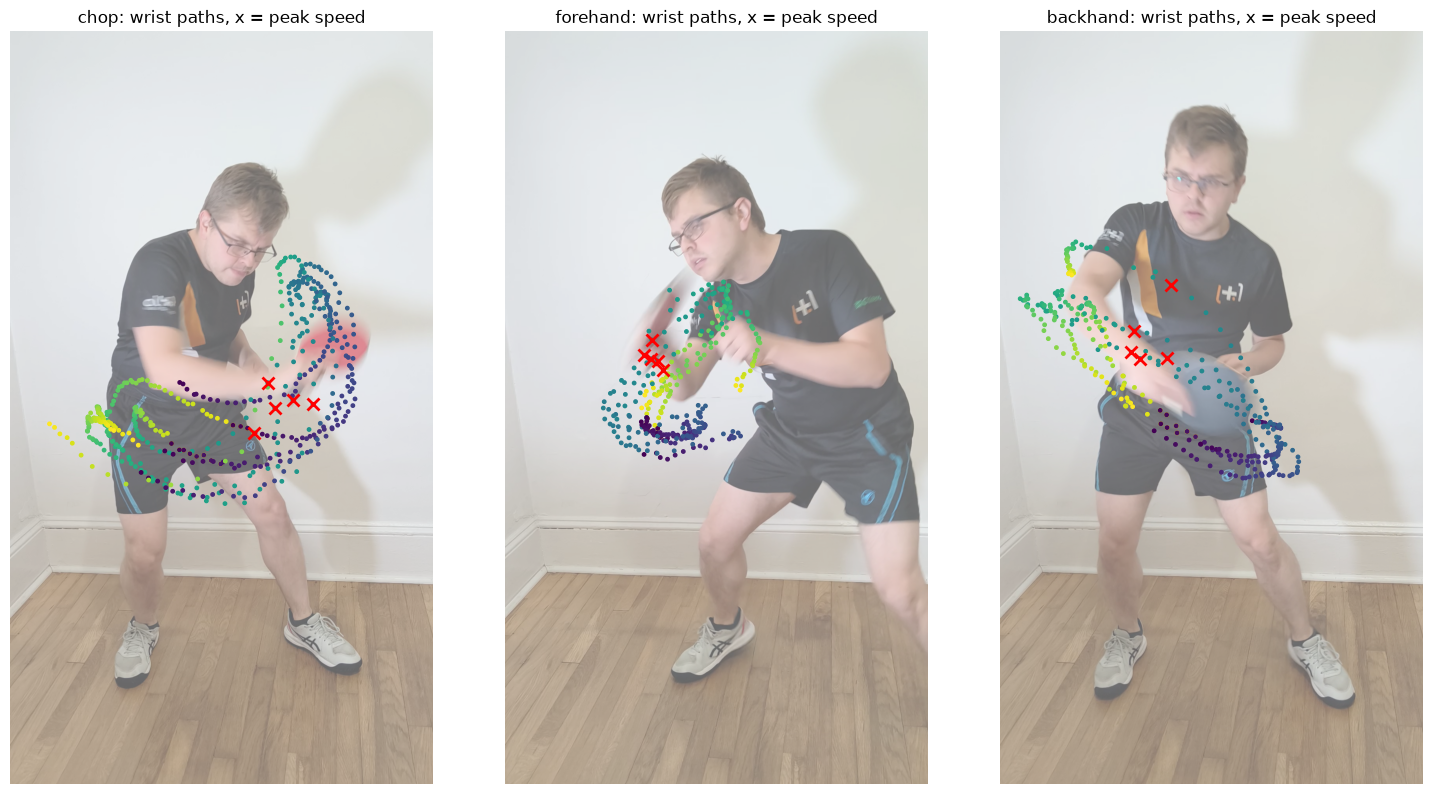

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 8))
for ax, c in zip(axs, CLIPS):
    k = K[c, "rtmpose"]; t = k["t"]; h = k["half"]; p0 = k["peaks"][0]
    ax.imshow(cv2.cvtColor(grab(c, [p0])[p0], cv2.COLOR_BGR2RGB), alpha=0.6)
    for p in k["peaks"]:
        lo, hi = max(0, p - h), min(len(t), p + h + 1)
        ax.scatter(*k["xy"][lo:hi, WR].T, c=np.linspace(0, 1, hi - lo), cmap="viridis", s=6)
        ax.plot(*k["xy"][p, WR], "rx", ms=8, mew=2)
    ax.set_title(f"{CLIPS[c]}: wrist paths, x = peak speed"); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Model agreement and motion blur
Per frame: median distance between the two models over the 17 joints, and the right-wrist distance, both in % of torso length, against wrist speed. If fast frames (blur) degrade the keypoints, the wrist disagreement should grow with speed. The confidence of each model on the wrist is shown the same way.

chop      median all-joint gap  3.9 % | wrist gap: slow half  4.3 %, fastest 10 %  5.7 % | RTMPose wrist score slow 0.92, fast 0.76
forehand  median all-joint gap  4.8 % | wrist gap: slow half  5.1 %, fastest 10 %  8.4 % | RTMPose wrist score slow 0.83, fast 0.79
backhand  median all-joint gap  4.1 % | wrist gap: slow half  4.9 %, fastest 10 % 10.2 % | RTMPose wrist score slow 0.88, fast 0.81


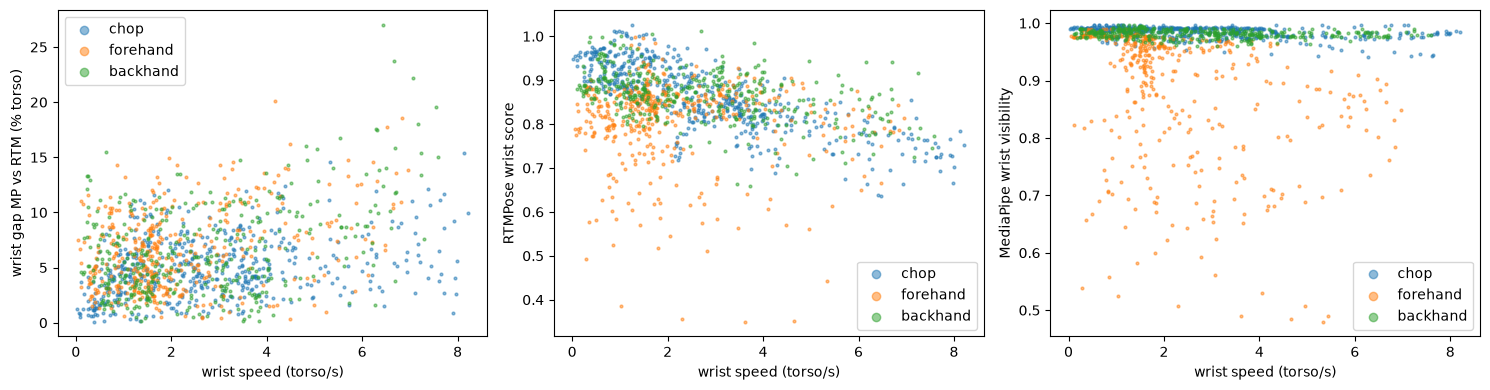

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for c in CLIPS:
    a, b = K[c, "mediapipe"], K[c, "rtmpose"]
    d = np.linalg.norm(a["xy"] - b["xy"], axis=2) / b["torso"] * 100
    v = b["v"]
    axs[0].scatter(v, d[:, WR], s=4, alpha=0.5, label=CLIPS[c])
    axs[1].scatter(v, b["conf"][:, WR], s=4, alpha=0.5, label=CLIPS[c])
    axs[2].scatter(v, a["conf"][:, WR], s=4, alpha=0.5, label=CLIPS[c])
    fast = v > np.percentile(v, 90); slow = v < np.percentile(v, 50)
    print(f"{CLIPS[c]:<9} median all-joint gap {np.median(d):4.1f} % | wrist gap: slow half {np.median(d[slow, WR]):4.1f} %, "
          f"fastest 10 % {np.median(d[fast, WR]):4.1f} % | RTMPose wrist score slow {np.median(b['conf'][slow, WR]):.2f}, "
          f"fast {np.median(b['conf'][fast, WR]):.2f}")
axs[0].set_ylabel("wrist gap MP vs RTM (% torso)"); axs[1].set_ylabel("RTMPose wrist score"); axs[2].set_ylabel("MediaPipe wrist visibility")
for ax in axs: ax.set_xlabel("wrist speed (torso/s)"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

## 8. Annotated videos
Each clip with both skeletons and a 0.5 s trail of the RTMPose wrist, encoded with ffmpeg (H.264, standard range, plays everywhere) to `data/derived/TableTennis1/vids/<clip>_annotated.mp4`. Written at the source frame rate; regenerable.

In [13]:
COL = {"mediapipe": (0, 140, 255), "rtmpose": (200, 110, 30)}  # BGR
for c in CLIPS:
    out = DER / f"{c}_annotated.mp4"
    t = T[c]; fps = (len(t) - 1) / (t[-1] - t[0])
    h, w = 1920, 1080
    ff = subprocess.Popen(["ffmpeg", "-y", "-v", "error", "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{w}x{h}",
                           "-r", f"{fps:.4f}", "-i", "-", "-c:v", "libx264", "-crf", "20", "-pix_fmt", "yuv420p", str(out)],
                          stdin=subprocess.PIPE)
    trail = int(0.5 * fps)
    for i, fr in enumerate(iter_frames(VIDS / f"{c}.mp4")):
        for m, col in COL.items():
            pts = K[c, m]["xy"][i]
            if np.isnan(pts).any(): continue
            pts = np.round(pts).astype(int)
            for a, b in EDGES:
                cv2.line(fr, tuple(pts[a]), tuple(pts[b]), col, 3, cv2.LINE_AA)
        tr = np.round(K[c, "rtmpose"]["xy"][max(0, i - trail):i + 1, WR]).astype(np.int32)
        cv2.polylines(fr, [tr], False, (0, 255, 0), 3, cv2.LINE_AA)
        cv2.putText(fr, f"{CLIPS[c]}  t={t[i]:.2f}s  v={K[c, 'rtmpose']['v'][i]:.1f} torso/s", (20, 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.4, (0, 0, 0), 3, cv2.LINE_AA)
        ff.stdin.write(fr.tobytes())
    ff.stdin.close(); ff.wait()
    print(out.relative_to(ROOT), f"{out.stat().st_size/1e6:.1f} MB")

data/derived/TableTennis1/vids/chop60_annotated.mp4 9.7 MB


data/derived/TableTennis1/vids/derecha60_annotated.mp4 8.7 MB


data/derived/TableTennis1/vids/reves60_annotated.mp4 7.3 MB


## Takeaways (2026-11-18, three 60 fps clips, front view, 5 strokes each)
- **Files:** normal 8-bit SDR H.264, full-range colour, rotation flag -90. No colour filter in the data. The "filter" look is most likely the player mis-handling full range and/or rotation [assumed]. Frame timing is clean: 16.67 ms spacing, no dropped frames. Slow-motion clips are 480 fps capture written as 30 fps (16x stretched), 1280x720, tighter framing.
- **Speed (CPU):** MediaPipe in VIDEO mode 21-27 ms per frame (about 40 fps, faster than IMAGE mode on stills). RTMPose with the detector on every frame 374-446 ms per frame (about 2.5 fps), so the three clips (1298 frames) take about 9 min. Both models found the person in every frame.
- **Strokes:** after adding a relative height rule, both models find 5 strokes in each clip, with peak times agreeing within 0.05 s (3 frames). Periods: chop 1.77 s, forehand 1.05 s, backhand 1.17 s.
- **Peak wrist speed** (smoothed, lower bound, torso/s): chop 7.6-8.1, forehand 6.5-7.0, backhand 6.9-7.9 (RTMPose-MediaPipe). Spread over strokes is 0.4-0.6 (5-8 %). MediaPipe reads about 1 torso/s higher than RTMPose on the backhand: that offset is the model, not the stroke. The 9-frame filter and the 60 fps sampling both cut the peak; the raw difference shows the forward swing lasts only a few frames.
- **Elbow angle:** usable for the chop (never masked; tight bundle: backswing minimum about 66-80 deg, extension to about 175 deg within 0.25 s). Not usable from this front view for the forehand and backhand: 33-41 % of frames are masked (arm pointing at the camera), and the forehand follow-through collapses to about 0 deg in projection. A side view is needed for those elbow angles.
- **"Elbow at peak speed" is a fragile metric at 60 fps:** around the peak the elbow changes by about 10 deg per frame, so a 1-frame difference in the peak changes it by about 10 deg. This explains most of its spread (std 6-23 deg) and the model gap. Prefer quantities from flat parts of the curve (backswing minimum), or use 480 fps.
- **Motion blur shows in the numbers:** the wrist gap between models grows from 4-5 % of torso (slow half of the frames) to 6-10 % (fastest 10 %), and the RTMPose wrist score drops (chop 0.92 to 0.76). The fastest frames, the ones that matter, are the least reliable.
- **Outlier strokes:** the first chop starts from rest, and the last backhand ends the sequence (elbow drops to about 40 deg). For consistency statistics, record 10+ strokes and drop the first and last.
- **Next:** the 480 fps clips (timestamps / 16, tighter framing: check that wrists and elbows stay in frame), a side-view clip for forehand and backhand elbow angles, and a filtering stage that writes `keypoints_<model>_filt.csv`.